# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [2]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: NVIDIA GeForce RTX 5070 VRAM GiB: 11.9
PyTorch: 2.11.0+cu128 torchvision: 0.26.0+cu128
Local cache: d:\Aa GXT Files\Code\EECS 280A\Project_Web\UCB_EECS280A_Project_Web\projects\project3\.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [3]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [4]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu128', 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 5070', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [5]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.GELU(),
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.GELU(),
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        # raise NotImplementedError()


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.GELU(),
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        # raise NotImplementedError()


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(nn.AvgPool2d(kernel_size=7), nn.GELU())
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        # raise NotImplementedError()


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            nn.ConvTranspose2d(in_channels, in_channels, kernel_size=7, stride=7, padding=0),
            nn.BatchNorm2d(in_channels),
            nn.GELU(),
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        # raise NotImplementedError()


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            Conv(in_channels, out_channels),
            Conv(out_channels, out_channels),
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        # raise NotImplementedError()


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            DownConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels),
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        # raise NotImplementedError()


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            UpConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels),
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        # raise NotImplementedError()

## Implementing Unconditional UNet

In [6]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens
        self.in_block = ConvBlock(in_channels, D)     # 1  -> D,  28x28
        self.down1 = DownBlock(D, D)                  # D  -> D,  14x14
        self.down2 = DownBlock(D, 2 * D)              # D  -> 2D, 7x7
        self.flatten = Flatten()                      # 2D, 7x7 -> 1x1
        self.unflatten = Unflatten(2 * D)             # 2D, 1x1 -> 7x7
        self.up1 = UpBlock(4 * D, D)                  # cat(2D,2D)=4D -> D, 14x14
        self.up2 = UpBlock(2 * D, D)                  # cat(D,D)=2D   -> D, 28x28
        self.out_block = ConvBlock(2 * D, D)          # cat(D,D)=2D   -> D, 28x28
        self.out_conv = nn.Conv2d(D, in_channels, kernel_size=3, stride=1, padding=1)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        e0 = self.in_block(x)                             # (N, D, 28, 28)
        e1 = self.down1(e0)                               # (N, D, 14, 14)
        e2 = self.down2(e1)                               # (N, 2D, 7, 7)

        b = self.flatten(e2)                              # (N, 2D, 1, 1)
        u0 = self.unflatten(b)                            # (N, 2D, 7, 7)

        u1 = self.up1(torch.cat([e2, u0], dim=1))         # (N, D, 14, 14)
        u2 = self.up2(torch.cat([e1, u1], dim=1))         # (N, D, 28, 28)
        out = self.out_block(torch.cat([e0, u2], dim=1))  # (N, D, 28, 28)
        return self.out_conv(out)                         # (N, 1, 28, 28)
        # ===== end of code ====
        # raise NotImplementedError()

# Part 1.2: Using the UNet to Train a Denoiser

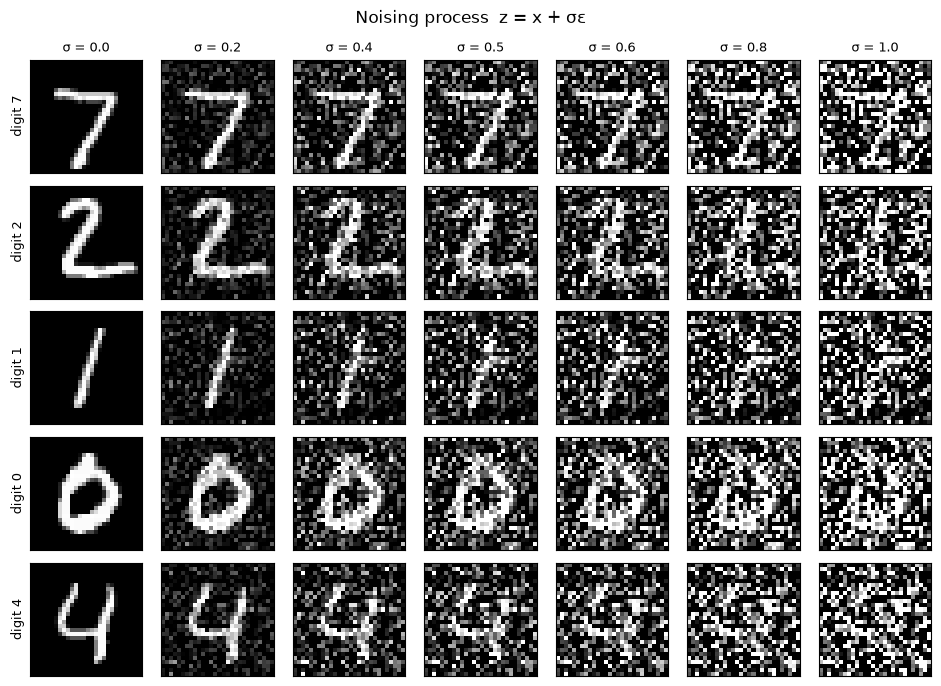

In [8]:
# Visualize images at different noisy level
# ===== your code here! ====
def show_table(rows, row_labels, col_labels, title, filename, scale=1.25):
    """Display a table of 1x28x28 images: rows[r][c] -> one image.

    Images are clamped to [0, 1] for display only.
    """
    R, C = len(rows), len(rows[0])
    fig, axs = plt.subplots(R, C, figsize=(C * scale + 0.8, R * scale + 0.7), squeeze=False)
    for r in range(R):
        for c in range(C):
            ax = axs[r][c]
            ax.imshow(rows[r][c].detach().float().cpu().squeeze().clamp(0, 1),
                      cmap='gray', vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0 and col_labels is not None:
                ax.set_title(col_labels[c], fontsize=9)
            if c == 0 and row_labels is not None:
                ax.set_ylabel(row_labels[r], fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
vis_x = torch.stack([test_dataset[i][0] for i in range(5)])                 # (5, 1, 28, 28) in [0, 1]
vis_eps = torch.randn(vis_x.shape, generator=torch.Generator().manual_seed(SEED))
show_table([[x + s * e for s in sigmas] for x, e in zip(vis_x, vis_eps)],
           row_labels=[f'digit {test_dataset[i][1]}' for i in range(5)],
           col_labels=[f'σ = {s}' for s in sigmas],
           title='Noising process  z = x + σε',
           filename='noise_levels.png')
# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [8]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
hidden_dim = 128
num_epochs = 5

In [9]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
train_loader = make_loader(batch_size, seed=SEED)                           # shuffled, x in [0, 1]
test_loader = DataLoader(
    torch.utils.data.TensorDataset(test_dataset.data[:, None].float() / 255, test_dataset.targets),
    batch_size=batch_size, shuffle=False)

In [10]:
# Define your model, optimizer, and loss
# ===== your code here! ====
torch.manual_seed(SEED)
model = UnconditionalUNet(in_channels=1, num_hiddens=hidden_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
# ===== end of code ====

In [13]:
# Fixed held-out test digits + fixed noise, so epoch-1 and epoch-5 results are comparable.
eval_x, _ = next(iter(test_loader))
eval_x = eval_x[:10].to(device)
eval_z = eval_x + noise_level * torch.randn(eval_x.shape, generator=torch.Generator().manual_seed(SEED)).to(device)
snapshots = {}
# The training loops
train_losses = []
for epoch in range(num_epochs):
    model.train()
    for i, (images, _) in enumerate(tqdm(train_loader, desc=f'epoch {epoch+1}/{num_epochs}')):

        # ===== your code here! ====

        images = images.to(device, non_blocking=True)
        noisy = images + noise_level * torch.randn_like(images)   # fresh noise for every batch
        outputs = model(noisy)

        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())
        # Results on held-out test digits after epochs 1 and 5; save checkpoints.
        if epoch + 1 in (1, num_epochs):
            model.eval()
            with torch.no_grad():
                snapshots[epoch + 1] = model(eval_z).cpu()
            torch.save(model.state_dict(), OUT / f'denoiser_epoch{epoch+1}.pt')
    print(f'epoch {epoch+1}: mean loss {np.mean(train_losses[-len(train_loader):]):.5f}')

epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 1: mean loss 0.03133


epoch 2/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 2: mean loss 0.01608


epoch 3/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 3: mean loss 0.01109


epoch 4/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 4: mean loss 0.00934


epoch 5/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 5: mean loss 0.01207


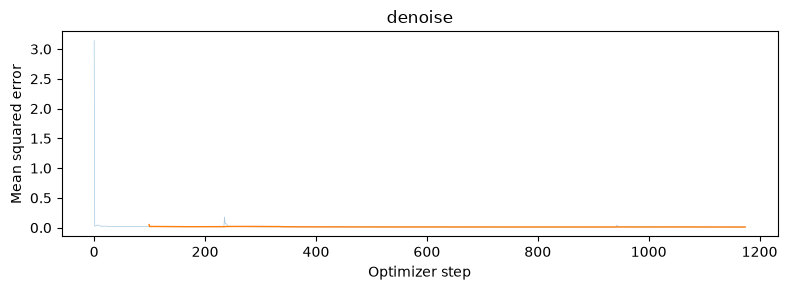

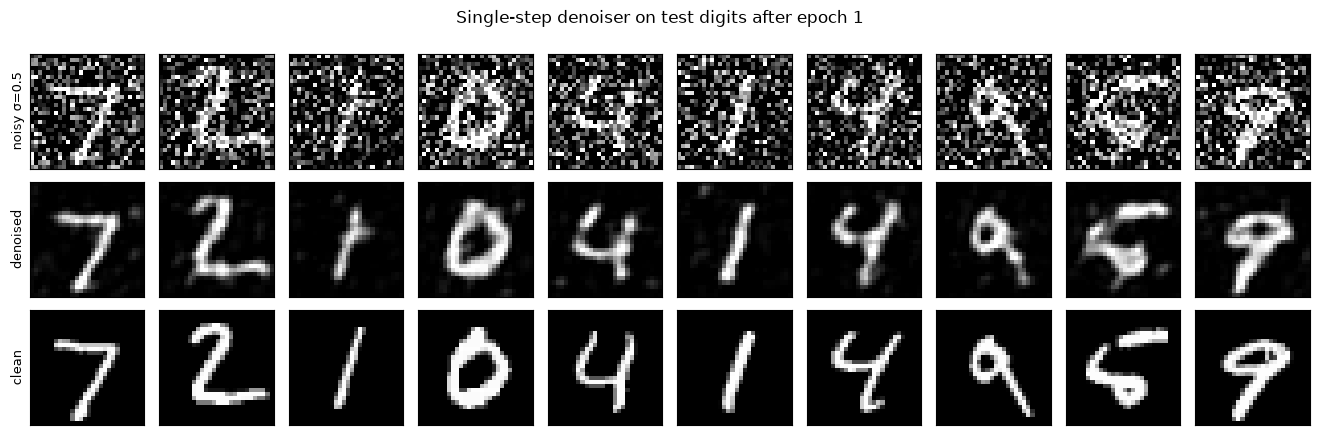

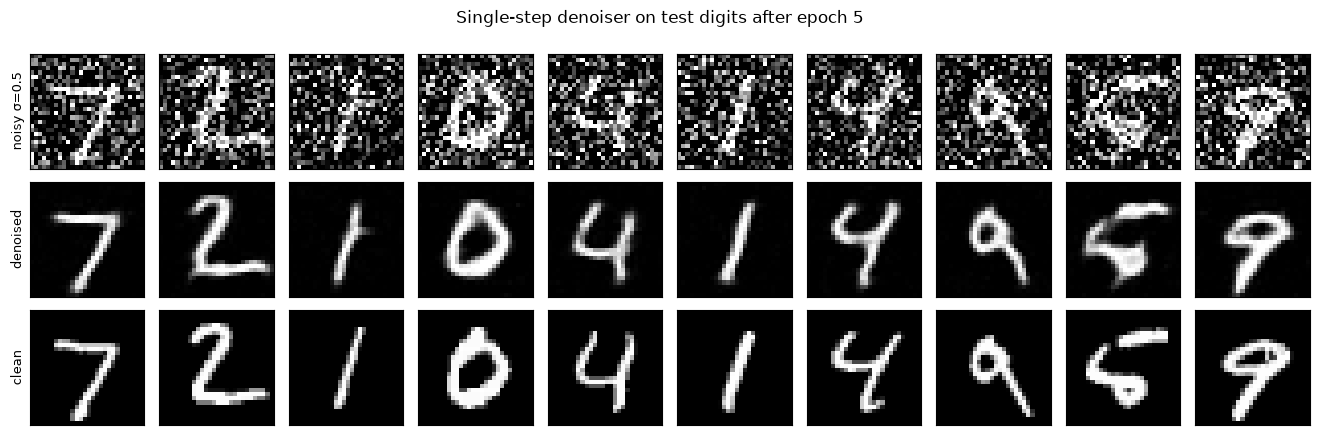

In [14]:
# Visualize your training curve
# ===== your code here! ====
loss_plot(train_losses, 'denoise')
for ep, out in snapshots.items():
    show_table([eval_z.cpu(), out, eval_x.cpu()],
               row_labels=['noisy σ=0.5', 'denoised', 'clean'], col_labels=None,
               title=f'Single-step denoiser on test digits after epoch {ep}',
               filename=f'denoise_epoch{ep}.png')
# ===== end of code ====

## Part 1.2.2: Out-of-Distribution Testing

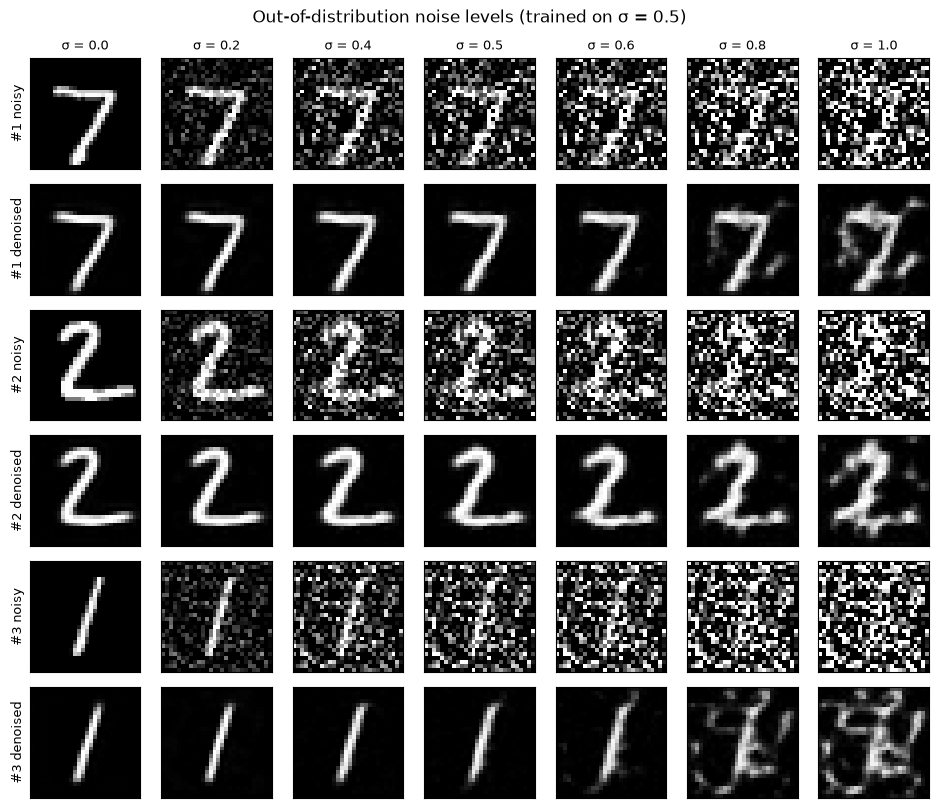

In [15]:
# Visualize OOD testing
# ===== your code here! ====
model.eval()
ood_x = eval_x[:3]                                                         # same 3 test digits for every σ
ood_eps = torch.randn(ood_x.shape, generator=torch.Generator().manual_seed(SEED + 1)).to(device)
rows, labels = [], []
with torch.no_grad():
    for k in range(len(ood_x)):
        noisy = [ood_x[k:k+1] + s * ood_eps[k:k+1] for s in sigmas]
        rows += [[z[0] for z in noisy], [model(z)[0] for z in noisy]]
        labels += [f'#{k+1} noisy', f'#{k+1} denoised']
show_table(rows, labels, [f'σ = {s}' for s in sigmas],
           'Out-of-distribution noise levels (trained on σ = 0.5)', 'denoise_ood.png')
# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

pure noise epoch 1/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 1: mean loss 0.06760


pure noise epoch 2/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 2: mean loss 0.06751


pure noise epoch 3/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 3: mean loss 0.06733


pure noise epoch 4/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 4: mean loss 0.06746


pure noise epoch 5/5:   0%|          | 0/235 [00:00<?, ?it/s]

epoch 5: mean loss 0.06750


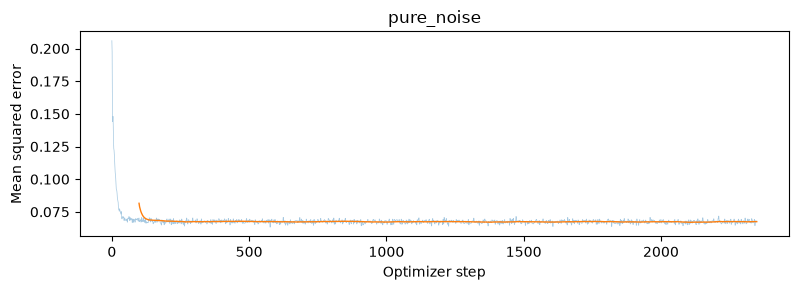

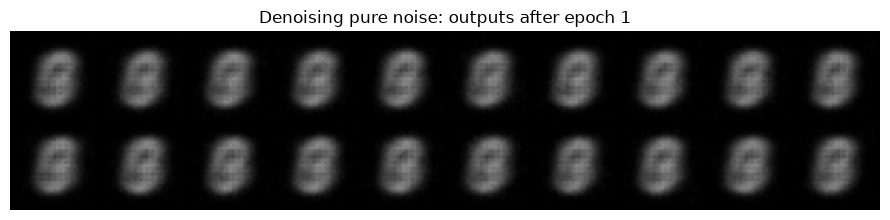

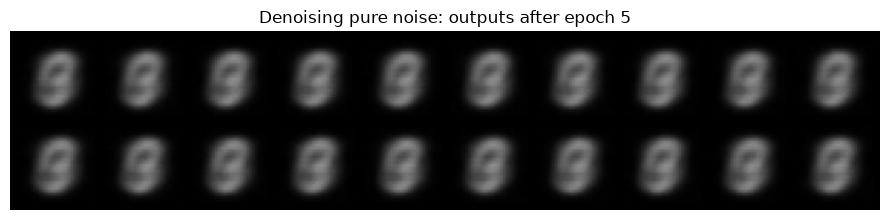

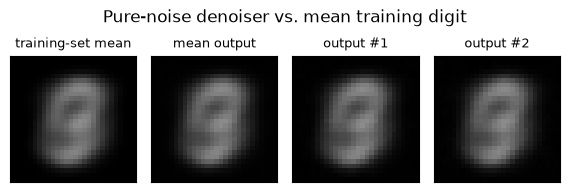

max |output - training mean| : 0.037336885929107666
std of outputs across inputs: 0.0039227125234901905


In [16]:
# Section 1.2.3: train a fresh D=128 UNet for 5 epochs, Adam lr=1e-4,
# batch size 256. Input is independent Gaussian noise, target is a clean digit.
# Plot losses, show held-out results at epochs 1 and 5, and explain averaging.
torch.manual_seed(SEED)
pure_model = UnconditionalUNet(in_channels=1, num_hiddens=hidden_dim).to(device)
pure_optimizer = torch.optim.Adam(pure_model.parameters(), lr=learning_rate)
pure_loader = make_loader(batch_size, seed=SEED)

# Fixed held-out pure-noise inputs (never seen in training).
pure_eval_z = torch.randn((20, 1, 28, 28), generator=torch.Generator().manual_seed(SEED + 2)).to(device)
pure_snapshots, pure_losses = {}, []
for epoch in range(num_epochs):
    pure_model.train()
    for images, _ in tqdm(pure_loader, desc=f'pure noise epoch {epoch+1}/{num_epochs}'):
        images = images.to(device, non_blocking=True)
        z = torch.randn_like(images)                       # input: pure noise, independent of the target
        loss = criterion(pure_model(z), images)
        pure_optimizer.zero_grad()
        loss.backward()
        pure_optimizer.step()
        pure_losses.append(loss.item())
        images = images.to(device, non_blocking=True)
        z = torch.randn_like(images)                       # input: pure noise, independent of the target
        loss = criterion(pure_model(z), images)
        pure_optimizer.zero_grad()
        loss.backward()
        pure_optimizer.step()
        pure_losses.append(loss.item())
    if epoch + 1 in (1, num_epochs):
        pure_model.eval()
        with torch.no_grad():
            pure_snapshots[epoch + 1] = pure_model(pure_eval_z).cpu()
        torch.save(pure_model.state_dict(), OUT / f'pure_noise_epoch{epoch+1}.pt')
    print(f'epoch {epoch+1}: mean loss {np.mean(pure_losses[-len(pure_loader):]):.5f}')

loss_plot(pure_losses, 'pure_noise')
for ep, out in pure_snapshots.items():
    show_grid(out, f'Denoising pure noise: outputs after epoch {ep}', f'pure_noise_epoch{ep}.png', nrow=10)

# Compare against the pixel-wise mean of the training set (the MSE-optimal constant prediction).
train_mean = (train_dataset.data.float() / 255).mean(0)[None, None]
out5 = pure_snapshots[num_epochs]
show_table([[train_mean[0], out5.mean(0), out5[0], out5[1]]], None,
           ['training-set mean', 'mean output', 'output #1', 'output #2'],
           'Pure-noise denoiser vs. mean training digit', 'pure_noise_vs_mean.png')
print('max |output - training mean| :', (out5 - train_mean).abs().max().item())
print('std of outputs across inputs:', out5.std(0).mean().item())

# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [11]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.net = nn.Sequential(
            nn.Linear(in_channels, out_channels),
            nn.GELU(),
            nn.Linear(out_channels, out_channels),
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.net(x)
        # ===== end of code ====
        # raise NotImplementedError()


class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        # num_classes is unused here (kept for a uniform signature with the class-conditional UNet).
        D = num_hiddens
        self.in_block = ConvBlock(in_channels, D)     # 1  -> D,  28x28
        self.down1 = DownBlock(D, D)                  # D  -> D,  14x14
        self.down2 = DownBlock(D, 2 * D)              # D  -> 2D, 7x7
        self.flatten = Flatten()                      # 2D, 7x7 -> 1x1
        self.unflatten = Unflatten(2 * D)             # 2D, 1x1 -> 7x7
        self.up1 = UpBlock(4 * D, D)                  # 4D -> D, 14x14
        self.up2 = UpBlock(2 * D, D)                  # 2D -> D, 28x28
        self.out_block = ConvBlock(2 * D, D)
        self.out_conv = nn.Conv2d(D, in_channels, kernel_size=3, stride=1, padding=1)
        # Time embeddings: scalar t -> per-channel modulation.
        self.fc1_t = FCBlock(1, 2 * D)                # modulates unflatten (2D x 7 x 7)
        self.fc2_t = FCBlock(1, D)                    # modulates up1 (D x 14 x 14)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N,) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        t = t.reshape(-1, 1).to(x.dtype)                  # (N, 1), already in [0, 1]
        t1 = self.fc1_t(t)[:, :, None, None]              # (N, 2D, 1, 1)
        t2 = self.fc2_t(t)[:, :, None, None]              # (N, D, 1, 1)

        e0 = self.in_block(x)                             # (N, D, 28, 28)
        e1 = self.down1(e0)                               # (N, D, 14, 14)
        e2 = self.down2(e1)                               # (N, 2D, 7, 7)

        u0 = self.unflatten(self.flatten(e2))             # (N, 2D, 7, 7)
        u0 = u0 * t1                                      # time modulation #1

        u1 = self.up1(torch.cat([e2, u0], dim=1))         # (N, D, 14, 14)
        u1 = u1 * t2                                      # time modulation #2

        u2 = self.up2(torch.cat([e1, u1], dim=1))         # (N, D, 28, 28)
        out = self.out_block(torch.cat([e0, u2], dim=1))  # (N, D, 28, 28)
        return self.out_conv(out)                         # (N, 1, 28, 28) predicted flow
        # ===== end of code ====
        # raise NotImplementedError()

## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [12]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    # num_ts is only used at sampling time; training uses continuous t ~ U[0, 1].
    N = x_1.shape[0]
    t = torch.rand(N, device=x_1.device)                       # t ~ U[0, 1]
    x_0 = torch.randn_like(x_1)                                # x_0 ~ N(0, I)
    tt = t.view(N, 1, 1, 1)
    x_t = (1 - tt) * x_0 + tt * x_1                            # linear interpolation
    pred = unet(x_t, t)                                        # predicted flow u_theta(x_t, t)
    return F.mse_loss(pred, x_1 - x_0)                         # target flow x_1 - x_0
    # ===== end of code ====
    # raise NotImplementedError()

In [13]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 2

    Args:
        unet: TimeConditionalUNet
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    # ===== your code here! ====
    n_samples = 40                                                     # 4 rows x 10 images
    dev = next(unet.parameters()).device
    g = torch.Generator().manual_seed(seed)
    x = torch.randn((n_samples, 1, *img_wh), generator=g).to(dev)     # x_0 ~ N(0, I)
    dt = 1.0 / num_ts
    for i in range(num_ts):                                            # t = 0, 1/T, ..., (T-1)/T
        t = torch.full((n_samples,), i * dt, device=dev)
        x = x + dt * unet(x, t)                                        # Euler step
    return x
    # ===== end of code ====
    # raise NotImplementedError()

In [14]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

time FM epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

epoch 1: mean loss 0.1663, next lr 7.94e-03


time FM epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

epoch 2: mean loss 0.1162, next lr 6.31e-03


time FM epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

...

epoch 8: mean loss 0.0929, next lr 1.58e-03


time FM epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

epoch 9: mean loss 0.0919, next lr 1.26e-03


time FM epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

epoch 10: mean loss 0.0908, next lr 1.00e-03


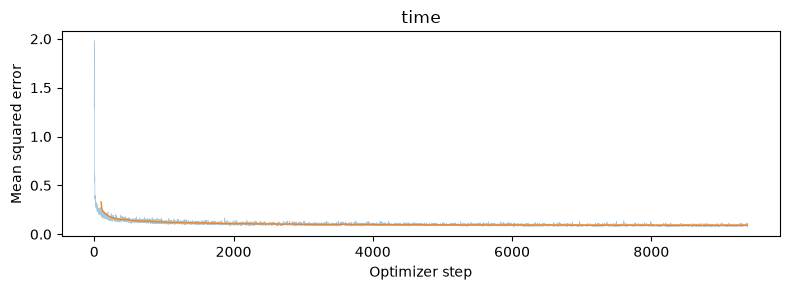

In [24]:
# Feel free to use code from part 1.2.1
# as they should be very similar
# ===== your code here! ====
time_batch_size = 64
time_lr = 1e-2
time_hidden = 64
time_epochs = 10
time_num_ts = 50
save_epochs = (1, 5, 10)

torch.manual_seed(SEED)
time_fm = TimeConditionalFM(
    TimeConditionalUNet(in_channels=1, num_classes=10, num_hiddens=time_hidden),
    num_ts=time_num_ts).to(device)
time_optimizer = torch.optim.Adam(time_fm.parameters(), lr=time_lr)
time_scheduler = torch.optim.lr_scheduler.ExponentialLR(time_optimizer, gamma=0.1 ** (1.0 / time_epochs))
time_loader = make_loader(time_batch_size, seed=SEED)

time_losses, time_samples = [], {}
for epoch in range(time_epochs):
    for images, _ in tqdm(time_loader, desc=f'time FM epoch {epoch+1}/{time_epochs}'):
        images = images.to(device, non_blocking=True)
        loss = time_fm(images)                     # Algorithm B.1 (noise drawn inside, per batch)
        time_optimizer.zero_grad()
        loss.backward()
        time_optimizer.step()
        time_losses.append(loss.item())
    time_scheduler.step()                          # once per epoch
    if epoch + 1 in save_epochs:
        torch.save(time_fm.unet.state_dict(), OUT / f'time_fm_epoch{epoch+1}.pt')
        time_samples[epoch + 1] = time_fm.sample((28, 28), seed=SEED).cpu()   # same noise every time
    print(f'epoch {epoch+1}: mean loss {np.mean(time_losses[-len(time_loader):]):.4f}, '
          f'next lr {time_scheduler.get_last_lr()[0]:.2e}')

loss_plot(time_losses, 'time')
# ===== end of code ====

# Part 2.3: Sampling from the Time-conditioned UNet

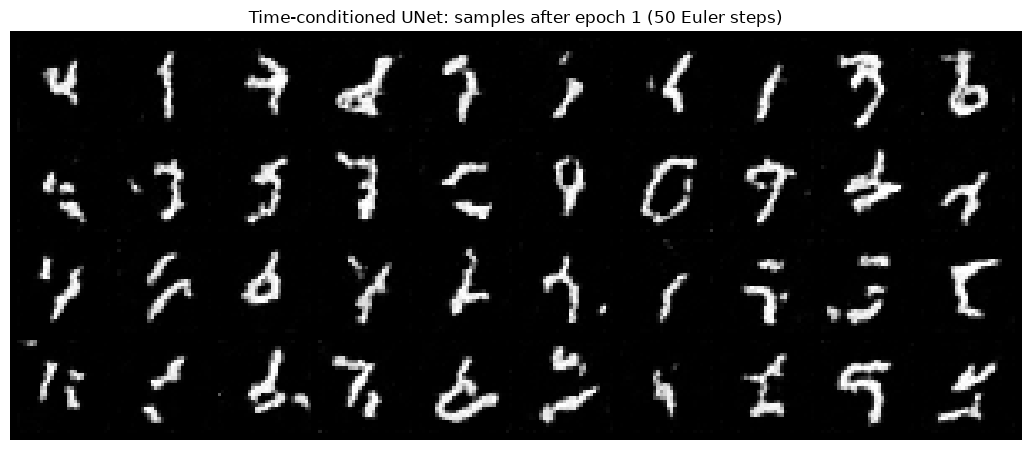

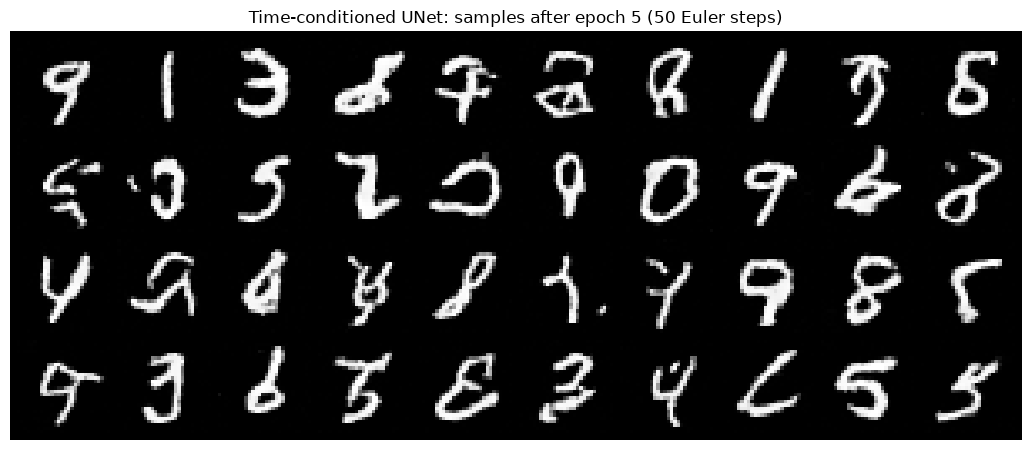

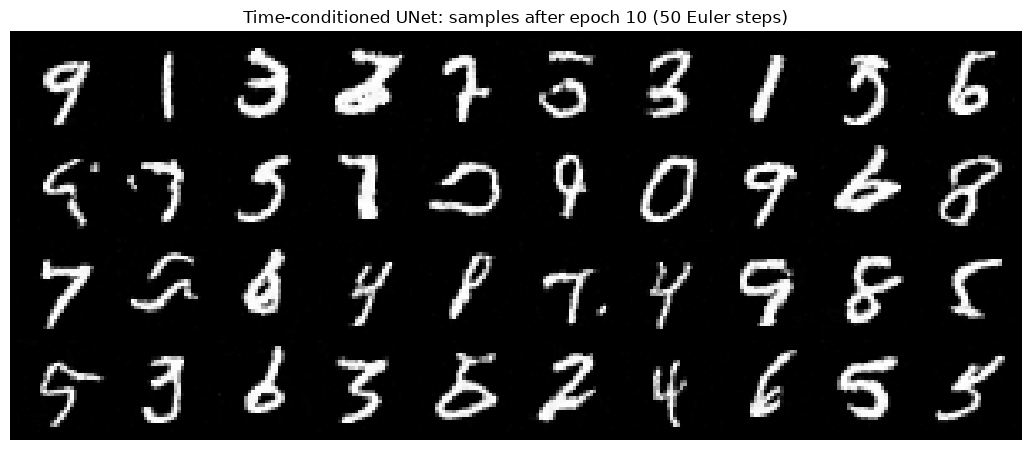

In [25]:
# Sampling from the UNet
# ===== your code here! ====
for ep, samples in time_samples.items():
    show_grid(samples, f'Time-conditioned UNet: samples after epoch {ep} ({time_num_ts} Euler steps)',
              f'time_epoch{ep}.png', nrow=10)
# ===== end of code ====

# Part 2.4: Implementing a Class-conditioned UNet

In [15]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens
        self.num_classes = num_classes
        self.in_block = ConvBlock(in_channels, D)     # 1  -> D,  28x28
        self.down1 = DownBlock(D, D)                  # D  -> D,  14x14
        self.down2 = DownBlock(D, 2 * D)              # D  -> 2D, 7x7
        self.flatten = Flatten()                      # 2D, 7x7 -> 1x1
        self.unflatten = Unflatten(2 * D)             # 2D, 1x1 -> 7x7
        self.up1 = UpBlock(4 * D, D)                  # 4D -> D, 14x14
        self.up2 = UpBlock(2 * D, D)                  # 2D -> D, 28x28
        self.out_block = ConvBlock(2 * D, D)
        self.out_conv = nn.Conv2d(D, in_channels, kernel_size=3, stride=1, padding=1)
        # Conditioning: time t (scalar) and class c (one-hot vector).
        self.fc1_t = FCBlock(1, 2 * D)
        self.fc1_c = FCBlock(num_classes, 2 * D)
        self.fc2_t = FCBlock(1, D)
        self.fc2_c = FCBlock(num_classes, D)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.
            t: (N,) normalized time tensor.
            mask: (N,) mask tensor. If not None, mask out condition when mask == 0.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        c = F.one_hot(c.long(), self.num_classes).to(x.dtype)    # (N, 10) one-hot
        if mask is not None:
            c = c * mask.reshape(-1, 1).to(x.dtype)               # mask == 0 -> zero vector (unconditional)
        t = t.reshape(-1, 1).to(x.dtype)                          # (N, 1)

        t1 = self.fc1_t(t)[:, :, None, None]                      # (N, 2D, 1, 1)
        c1 = self.fc1_c(c)[:, :, None, None]                      # (N, 2D, 1, 1)
        t2 = self.fc2_t(t)[:, :, None, None]                      # (N, D, 1, 1)
        c2 = self.fc2_c(c)[:, :, None, None]                      # (N, D, 1, 1)

        e0 = self.in_block(x)                                     # (N, D, 28, 28)
        e1 = self.down1(e0)                                       # (N, D, 14, 14)
        e2 = self.down2(e1)                                       # (N, 2D, 7, 7)

        u0 = self.unflatten(self.flatten(e2))                     # (N, 2D, 7, 7)
        u0 = c1 * u0 + t1                                         # modulation #1

        u1 = self.up1(torch.cat([e2, u0], dim=1))                 # (N, D, 14, 14)
        u1 = c2 * u1 + t2                                         # modulation #2

        u2 = self.up2(torch.cat([e1, u1], dim=1))                 # (N, D, 28, 28)
        out = self.out_block(torch.cat([e0, u2], dim=1))          # (N, D, 28, 28)
        return self.out_conv(out)                                 # (N, 1, 28, 28) predicted flow
        # ===== end of code ====
        raise NotImplementedError()

In [16]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3

    Args:
        unet: ClassConditionalUNet
        x_1: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====
    N = x_1.shape[0]
    mask = (torch.rand(N, device=x_1.device) >= p_uncond).float()   # 0 with prob p_uncond -> drop class
    t = torch.rand(N, device=x_1.device)                            # t ~ U[0, 1]
    x_0 = torch.randn_like(x_1)                                     # x_0 ~ N(0, I)
    tt = t.view(N, 1, 1, 1)
    x_t = (1 - tt) * x_0 + tt * x_1
    pred = unet(x_t, c, t, mask)
    return F.mse_loss(pred, x_1 - x_0)
    # ===== end of code ====
    raise NotImplementedError()

In [17]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 4

    Args:
        unet: ClassConditionalUNet
        c: (N,) int64 condition tensor. Only for class-conditional
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
        (N, T_animation, C, H, W) caches.
    """
    unet.eval()
    # ===== your code here! ====
    dev = next(unet.parameters()).device
    c = c.to(dev)
    N = c.shape[0]
    g = torch.Generator().manual_seed(seed)
    x = torch.randn((N, 1, *img_wh), generator=g).to(dev)          # x_0 ~ N(0, I)
    ones, zeros = torch.ones(N, device=dev), torch.zeros(N, device=dev)
    dt = 1.0 / num_ts
    every = max(1, num_ts // 30)                                   # keep ~30 frames for animations
    caches = [x.cpu()]
    for i in range(num_ts):
        t = torch.full((N,), i * dt, device=dev)
        u_uncond = unet(x, c, t, zeros)                            # class dropped
        u_cond = unet(x, c, t, ones)                               # class given
        u = u_uncond + guidance_scale * (u_cond - u_uncond)        # classifier-free guidance
        x = x + dt * u                                             # Euler step
        if (i + 1) % every == 0 or i == num_ts - 1:
            caches.append(x.cpu())
    return x, torch.stack(caches, dim=1)                           # (N,C,H,W), (N,T_anim,C,H,W)
    # ===== end of code ====
    raise NotImplementedError()

In [18]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

In [19]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.
class_batch_size = 64
class_hidden = 64
class_epochs = 10
class_num_ts = 300
p_uncond = 0.1
guidance = 5.0
save_epochs = (1, 5, 10)
sample_c = torch.arange(10).repeat(4)          # 40 labels: each column of a 10-wide grid is one digit

class epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

[class] epoch 1: mean loss 0.1589, next lr 7.94e-03


class epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

[class] epoch 2: mean loss 0.1104, next lr 6.31e-03


class epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

...

[class] epoch 8: mean loss 0.0878, next lr 1.58e-03


class epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

[class] epoch 9: mean loss 0.0863, next lr 1.26e-03


class epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

[class] epoch 10: mean loss 0.0854, next lr 1.00e-03


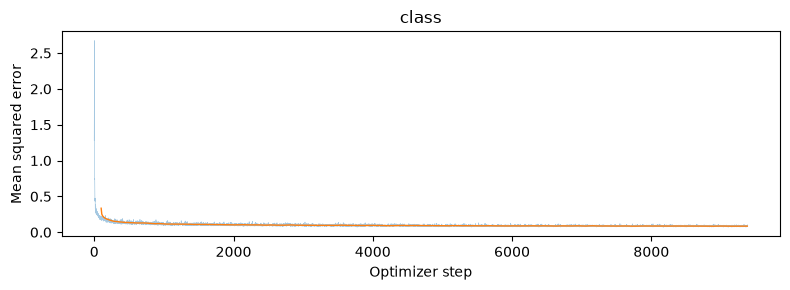

class_nosched epoch 1/10:   0%|          | 0/938 [00:00<?, ?it/s]

[class_nosched] epoch 1: mean loss 0.1308, next lr 1.00e-03


class_nosched epoch 2/10:   0%|          | 0/938 [00:00<?, ?it/s]

[class_nosched] epoch 2: mean loss 0.1027, next lr 1.00e-03


class_nosched epoch 3/10:   0%|          | 0/938 [00:00<?, ?it/s]

...

[class_nosched] epoch 8: mean loss 0.0859, next lr 1.00e-03


class_nosched epoch 9/10:   0%|          | 0/938 [00:00<?, ?it/s]

[class_nosched] epoch 9: mean loss 0.0849, next lr 1.00e-03


class_nosched epoch 10/10:   0%|          | 0/938 [00:00<?, ?it/s]

[class_nosched] epoch 10: mean loss 0.0844, next lr 1.00e-03


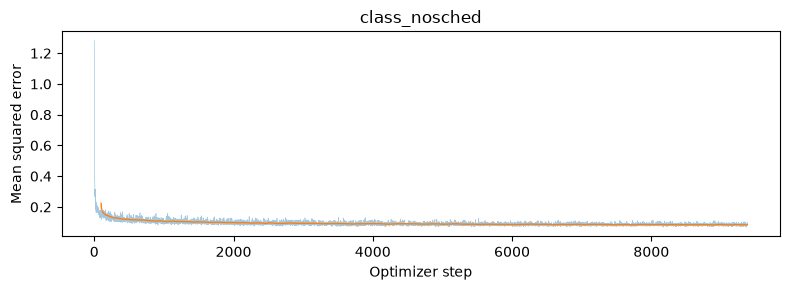

In [31]:
def train_class_fm(tag, lr, use_scheduler, grad_clip=None):
    """Train a fresh class-conditioned flow model; return (model, losses, {epoch: samples})."""
    torch.manual_seed(SEED)
    fm = ClassConditionalFM(
        ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=class_hidden),
        num_ts=class_num_ts, p_uncond=p_uncond).to(device)
    opt = torch.optim.Adam(fm.parameters(), lr=lr)
    sched = (torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.1 ** (1.0 / class_epochs))
             if use_scheduler else None)
    loader = make_loader(class_batch_size, seed=SEED)
    losses, samples = [], {}
    for epoch in range(class_epochs):
        for images, labels in tqdm(loader, desc=f'{tag} epoch {epoch+1}/{class_epochs}'):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            loss = fm(images, labels)                       # Algorithm B.3
            opt.zero_grad()
            loss.backward()
            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(fm.parameters(), grad_clip)
            opt.step()
            losses.append(loss.item())
        if sched is not None:
            sched.step()                                    # once per epoch
        if epoch + 1 in save_epochs:
            torch.save(fm.unet.state_dict(), OUT / f'{tag}_epoch{epoch+1}.pt')
            samples[epoch + 1], _ = fm.sample(sample_c, (28, 28), guidance_scale=guidance, seed=SEED)
            samples[epoch + 1] = samples[epoch + 1].cpu()
        print(f'[{tag}] epoch {epoch+1}: mean loss {np.mean(losses[-len(loader):]):.4f}, '
              f'next lr {opt.param_groups[0]["lr"]:.2e}')
    return fm, losses, samples


# (1) Required setting: Adam lr=1e-2 with exponential decay to 1e-3 over 10 epochs.
class_fm, class_losses, class_samples = train_class_fm('class', lr=1e-2, use_scheduler=True)
loss_plot(class_losses, 'class')

# (2) No scheduler: a constant lr instead of the decaying one.
# 1e-2 held constant is too large late in training (noisy, unstable updates), so we use
# a constant 1e-3 -- the value the scheduled run decays to -- and clip gradients for stability.
NO_SCHED_LR = 1e-3
nosched_fm, nosched_losses, nosched_samples = train_class_fm(
    'class_nosched', lr=NO_SCHED_LR, use_scheduler=False, grad_clip=1.0)
loss_plot(nosched_losses, 'class_nosched')

# Part 2.6: Sampling from the Class-conditioned UNet

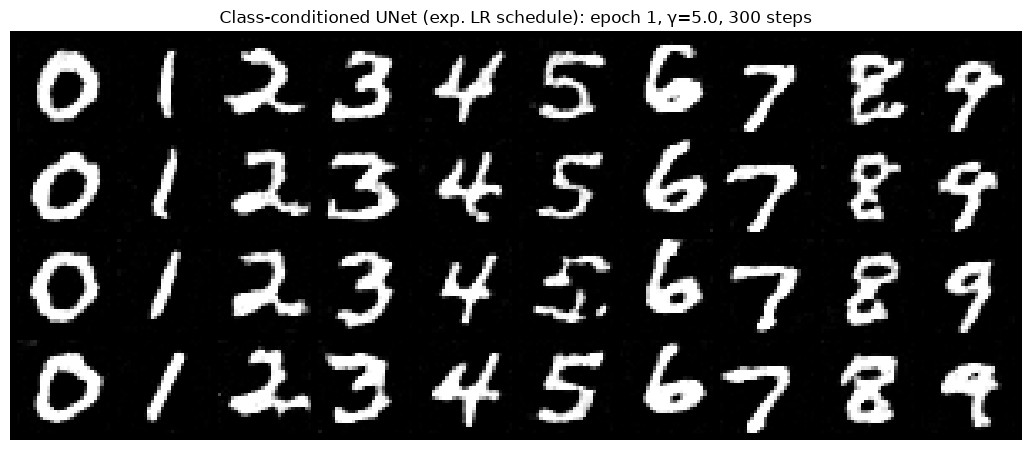

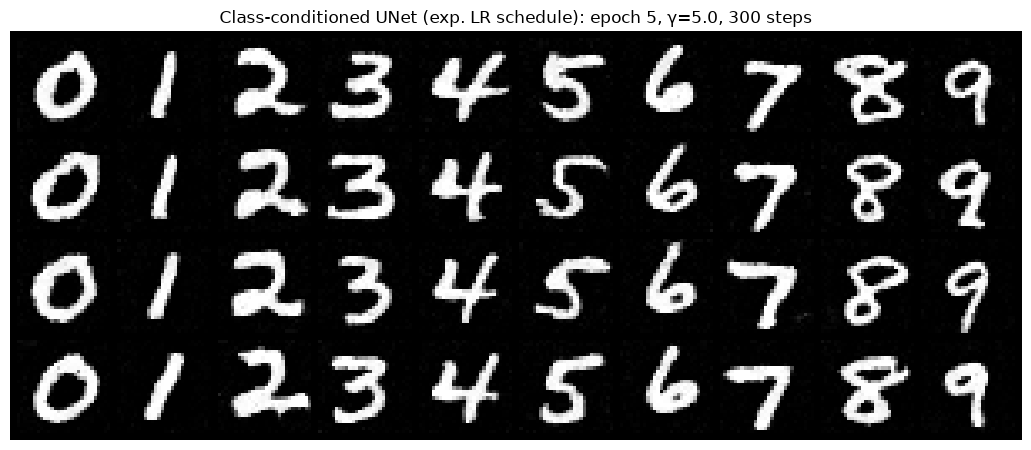

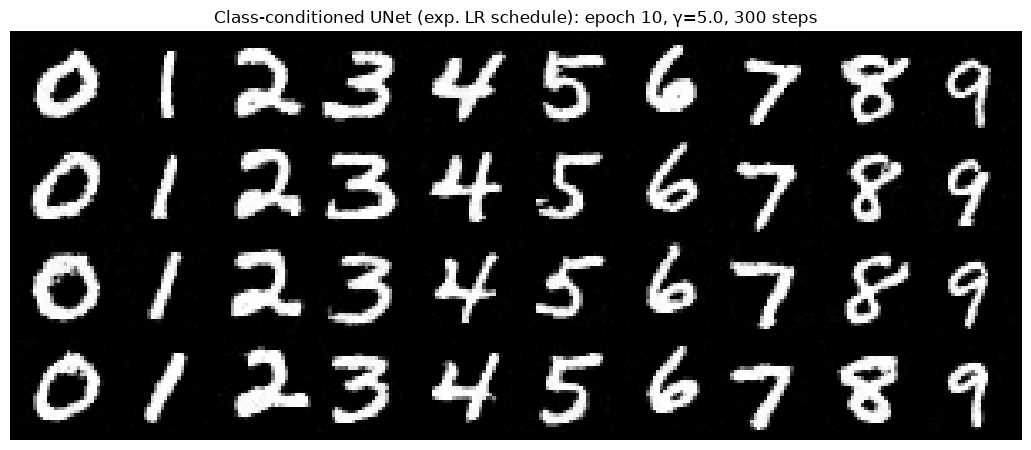

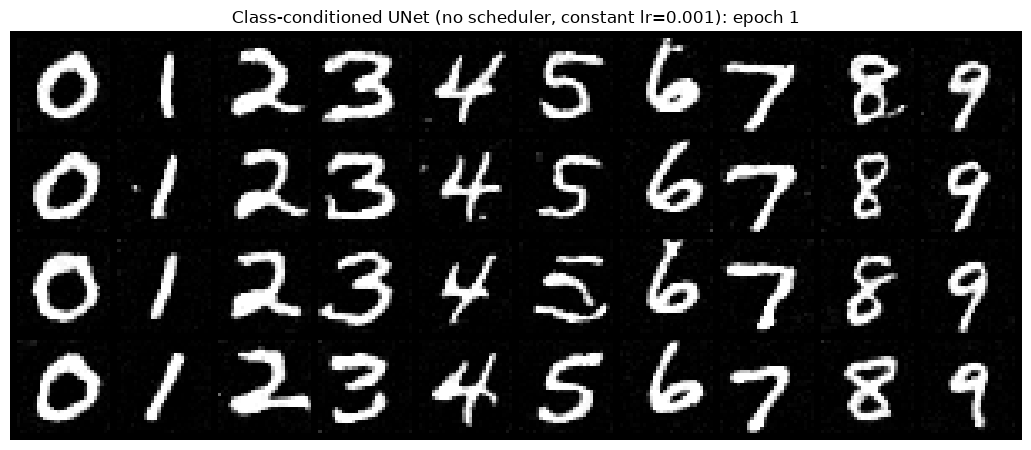

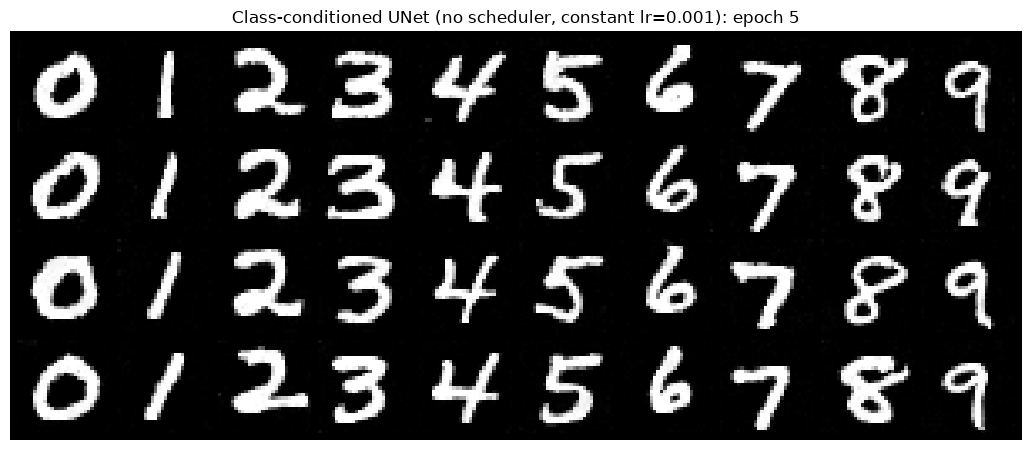

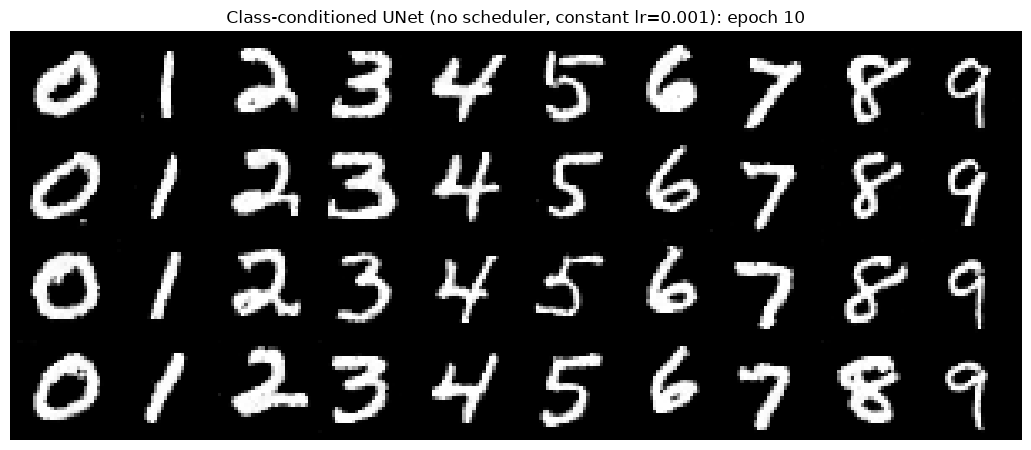

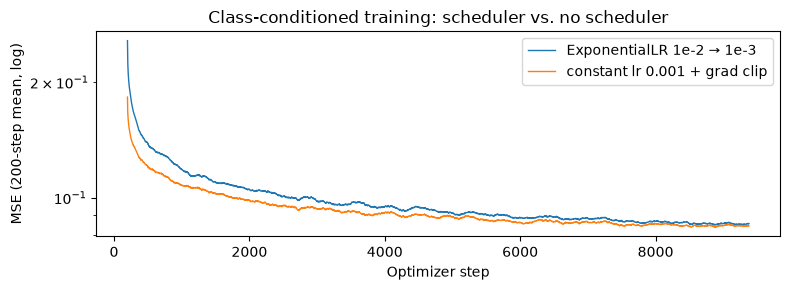

final-epoch mean loss  scheduled: 0.0854   no scheduler: 0.0844


In [32]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.
for ep, samples in class_samples.items():
    show_grid(samples, f'Class-conditioned UNet (exp. LR schedule): epoch {ep}, γ={guidance}, {class_num_ts} steps',
              f'class_epoch{ep}.png', nrow=10)
for ep, samples in nosched_samples.items():
    show_grid(samples, f'Class-conditioned UNet (no scheduler, constant lr={NO_SCHED_LR:g}): epoch {ep}',
              f'class_nosched_epoch{ep}.png', nrow=10)

# Loss comparison of the two runs (smoothed).
fig, ax = plt.subplots(figsize=(8, 3))
for losses, name in [(class_losses, 'ExponentialLR 1e-2 → 1e-3'),
                     (nosched_losses, f'constant lr {NO_SCHED_LR:g} + grad clip')]:
    smooth = torch.tensor(losses).unfold(0, 200, 1).mean(1)
    ax.plot(range(199, len(losses)), smooth, linewidth=1, label=name)
ax.set_yscale('log'); ax.set(xlabel='Optimizer step', ylabel='MSE (200-step mean, log)',
                             title='Class-conditioned training: scheduler vs. no scheduler')
ax.legend(); fig.tight_layout(); fig.savefig(OUT / 'class_scheduler_comparison_loss.png', dpi=120)
plt.show(); plt.close(fig)
print(f'final-epoch mean loss  scheduled: {np.mean(class_losses[-938:]):.4f}   '
      f'no scheduler: {np.mean(nosched_losses[-938:]):.4f}')

# Part 3: Bells & Whistles

In [22]:
import copy, math


def sinusoidal_embedding(t: torch.Tensor, dim: int) -> torch.Tensor:
    """Transformer-style Fourier features of t in [0, 1] -> (N, dim)."""
    half = dim // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
    args = 1000.0 * t.reshape(-1, 1).float() * freqs[None]          # scale t so frequencies span its range
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)


class FiLM(nn.Module):
    """Feature-wise linear modulation: h * (1 + scale(emb)) + shift(emb). Zero-init -> starts as identity."""
    def __init__(self, emb_dim: int, channels: int):
        super().__init__()
        self.proj = nn.Linear(emb_dim, 2 * channels)
        nn.init.zeros_(self.proj.weight); nn.init.zeros_(self.proj.bias)

    def forward(self, h: torch.Tensor, emb: torch.Tensor) -> torch.Tensor:
        scale, shift = self.proj(emb)[:, :, None, None].chunk(2, dim=1)
        return h * (1 + scale) + shift


class ImprovedTimeUNet(nn.Module):
    """Same UNet skeleton as Part 2, but with
    (1) sinusoidal time embedding + MLP instead of a raw scalar into an FCBlock,
    (2) FiLM (scale AND shift) at every resolution of encoder and decoder (6 places instead of 2),
    (3) wider default channels (D=128).
    """
    def __init__(self, in_channels: int = 1, num_hiddens: int = 128, emb_dim: int = 256):
        super().__init__()
        D = num_hiddens
        self.emb_dim = emb_dim
        self.time_mlp = nn.Sequential(nn.Linear(emb_dim, emb_dim), nn.GELU(), nn.Linear(emb_dim, emb_dim))
        self.in_block = ConvBlock(in_channels, D)
        self.down1 = DownBlock(D, D)
        self.down2 = DownBlock(D, 2 * D)
        self.flatten = Flatten()
        self.unflatten = Unflatten(2 * D)
        self.up1 = UpBlock(4 * D, D)
        self.up2 = UpBlock(2 * D, D)
        self.out_block = ConvBlock(2 * D, D)
        self.out_conv = nn.Conv2d(D, in_channels, kernel_size=3, stride=1, padding=1)
        self.film_e0 = FiLM(emb_dim, D)
        self.film_e1 = FiLM(emb_dim, D)
        self.film_e2 = FiLM(emb_dim, 2 * D)
        self.film_u0 = FiLM(emb_dim, 2 * D)
        self.film_u1 = FiLM(emb_dim, D)
        self.film_u2 = FiLM(emb_dim, D)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        emb = self.time_mlp(sinusoidal_embedding(t, self.emb_dim))     # (N, emb_dim)
        e0 = self.film_e0(self.in_block(x), emb)                        # (N, D, 28, 28)
        e1 = self.film_e1(self.down1(e0), emb)                          # (N, D, 14, 14)
        e2 = self.film_e2(self.down2(e1), emb)                          # (N, 2D, 7, 7)
        u0 = self.film_u0(self.unflatten(self.flatten(e2)), emb)        # (N, 2D, 7, 7)
        u1 = self.film_u1(self.up1(torch.cat([e2, u0], 1)), emb)        # (N, D, 14, 14)
        u2 = self.film_u2(self.up2(torch.cat([e1, u1], 1)), emb)        # (N, D, 28, 28)
        return self.out_conv(self.out_block(torch.cat([e0, u2], 1)))    # (N, 1, 28, 28)


@torch.no_grad()
def ema_update(ema_model: nn.Module, model: nn.Module, decay: float):
    """Exponential moving average of weights; BatchNorm running stats are copied."""
    for p_ema, p in zip(ema_model.parameters(), model.parameters()):
        p_ema.lerp_(p, 1 - decay)
    for b_ema, b in zip(ema_model.buffers(), model.buffers()):
        b_ema.copy_(b)




In [24]:
bw_epochs = 20
bw_batch_size = 128
bw_lr = 2e-3
bw_warmup = 500                 # linear warmup steps, then cosine decay to ~0
bw_ema_decay = 0.999
bw_save_epochs = (1, 5, 10, 20)

improved epoch 1/20:   0%|          | 0/469 [00:00<?, ?it/s]

epoch 1: mean loss 0.1634, lr 1.87e-03


improved epoch 2/20:   0%|          | 0/469 [00:00<?, ?it/s]

epoch 2: mean loss 0.1013, lr 1.95e-03


improved epoch 3/20:   0%|          | 0/469 [00:00<?, ?it/s]

...

epoch 18: mean loss 0.0828, lr 4.89e-05


improved epoch 19/20:   0%|          | 0/469 [00:00<?, ?it/s]

epoch 19: mean loss 0.0823, lr 1.23e-05


improved epoch 20/20:   0%|          | 0/469 [00:00<?, ?it/s]

epoch 20: mean loss 0.0828, lr 0.00e+00


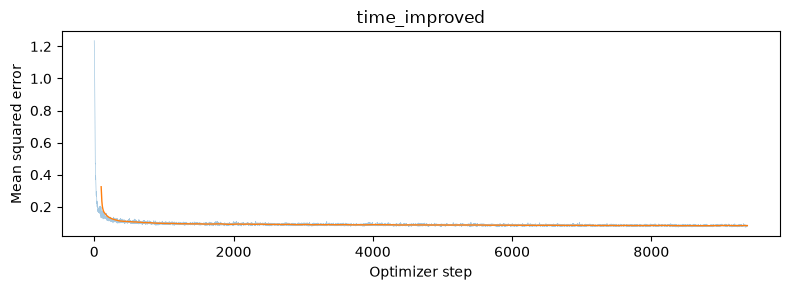

In [25]:
torch.manual_seed(SEED)
bw_unet = ImprovedTimeUNet(in_channels=1, num_hiddens=128).to(device)
bw_ema = copy.deepcopy(bw_unet).eval().requires_grad_(False)
bw_opt = torch.optim.AdamW(bw_unet.parameters(), lr=bw_lr, weight_decay=1e-4)
bw_loader = make_loader(bw_batch_size, seed=SEED)
bw_total = bw_epochs * len(bw_loader)
bw_sched = torch.optim.lr_scheduler.LambdaLR(
    bw_opt, lambda s: min(1.0, (s + 1) / bw_warmup) * 0.5 * (1 + math.cos(math.pi * min(s, bw_total) / bw_total)))

bw_losses, bw_samples = [], {}
for epoch in range(bw_epochs):
    for images, _ in tqdm(bw_loader, desc=f'improved epoch {epoch+1}/{bw_epochs}'):
        images = images.to(device, non_blocking=True)
        loss = time_fm_forward(bw_unet, images, num_ts=50)      # same flow-matching objective (Alg. B.1)
        bw_opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(bw_unet.parameters(), 1.0)
        bw_opt.step()
        bw_sched.step()                                         # per step (warmup + cosine)
        ema_update(bw_ema, bw_unet, bw_ema_decay)
        bw_losses.append(loss.item())
    if epoch + 1 in bw_save_epochs:
        torch.save(bw_ema.state_dict(), OUT / f'time_improved_ema_epoch{epoch+1}.pt')
        bw_samples[epoch + 1] = time_fm_sample(bw_ema, (28, 28), num_ts=50, seed=SEED).cpu()
    print(f'epoch {epoch+1}: mean loss {np.mean(bw_losses[-len(bw_loader):]):.4f}, '
          f'lr {bw_sched.get_last_lr()[0]:.2e}')

loss_plot(bw_losses, 'time_improved')

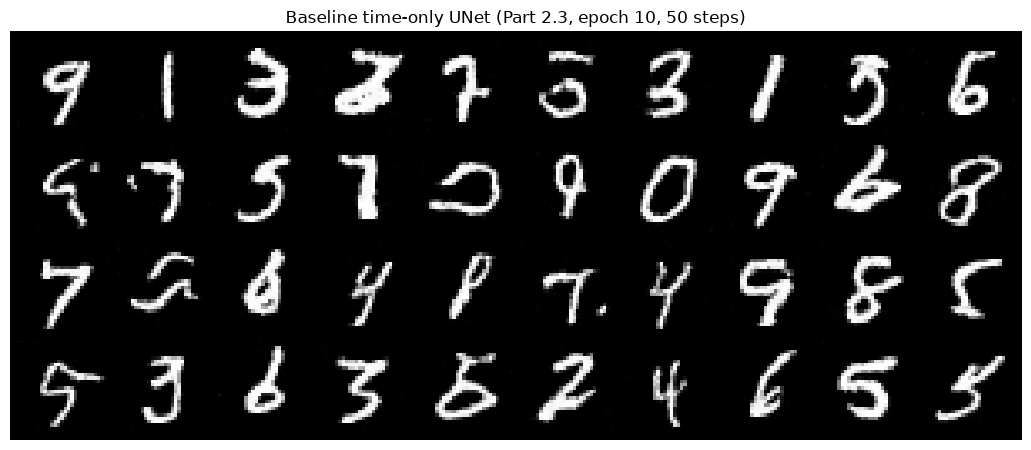

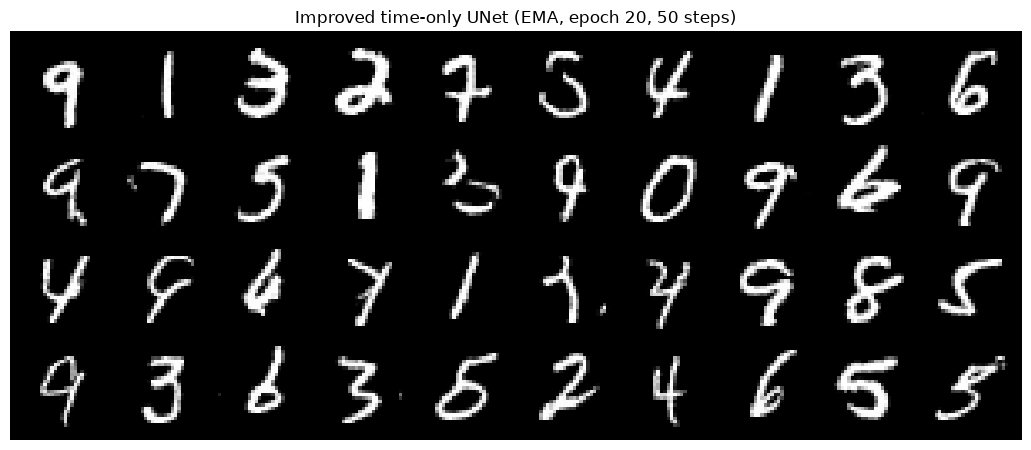

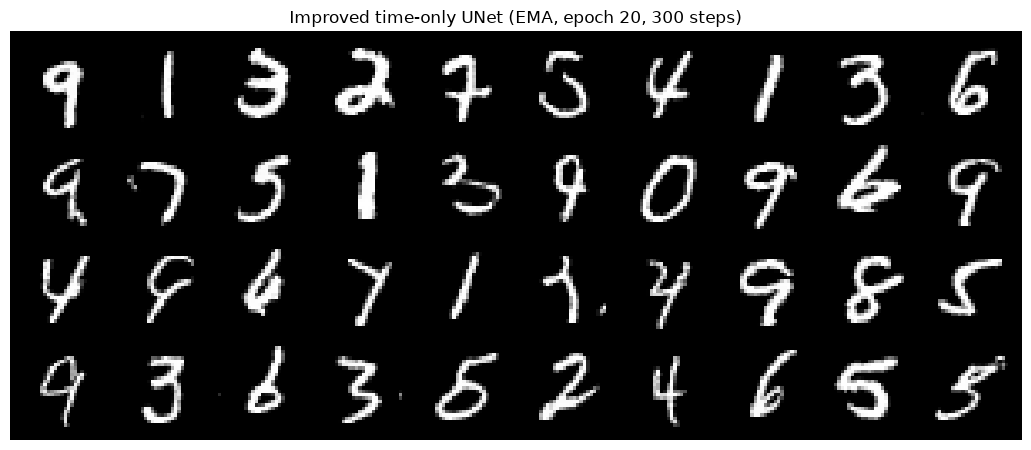

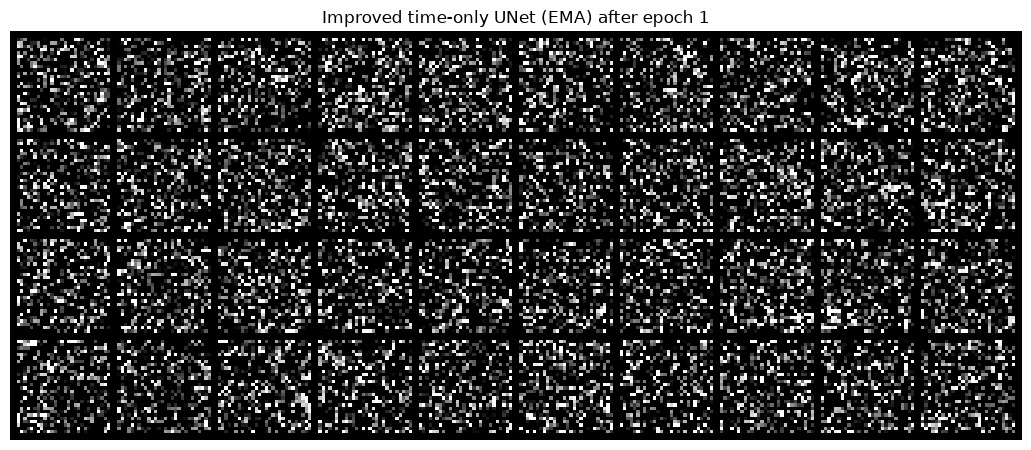

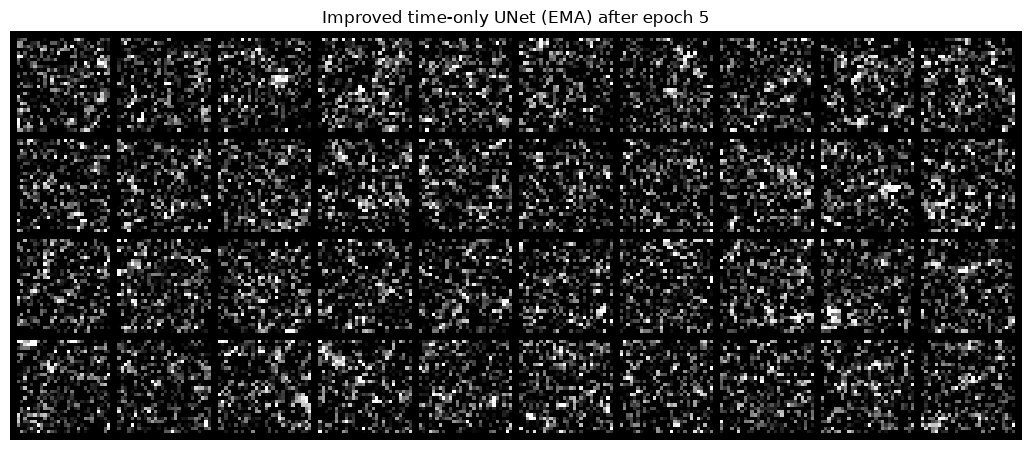

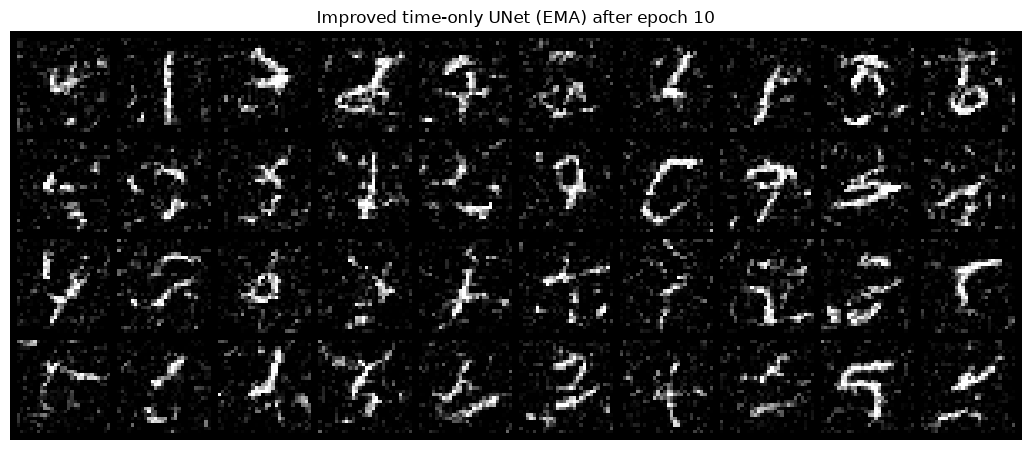

In [26]:
base_unet = TimeConditionalUNet(in_channels=1, num_classes=10, num_hiddens=64).to(device)
base_unet.load_state_dict(torch.load(OUT / 'time_fm_epoch10.pt', map_location=device))
base_samples = time_fm_sample(base_unet, (28, 28), num_ts=50, seed=SEED).cpu()
improved_samples = bw_samples[bw_epochs]
improved_samples_300 = time_fm_sample(bw_ema, (28, 28), num_ts=300, seed=SEED).cpu()

show_grid(base_samples, 'Baseline time-only UNet (Part 2.3, epoch 10, 50 steps)', 'time_baseline_epoch10.png', nrow=10)
show_grid(improved_samples, f'Improved time-only UNet (EMA, epoch {bw_epochs}, 50 steps)', 'time_improved.png', nrow=10)
show_grid(improved_samples_300, f'Improved time-only UNet (EMA, epoch {bw_epochs}, 300 steps)', 'time_improved_300steps.png', nrow=10)
for ep, s in bw_samples.items():
    if ep != bw_epochs:
        show_grid(s, f'Improved time-only UNet (EMA) after epoch {ep}', f'time_improved_epoch{ep}.png', nrow=10)

In [27]:
# Train a quick CNN classifier (~99% test accuracy). For generated samples we report
#  - mean max-softmax confidence (how "digit-like" / unambiguous samples are),
#  - fraction of samples classified with confidence > 0.9,
#  - entropy of the predicted-class histogram (diversity; max = ln 10 = 2.303).
torch.manual_seed(SEED)
clf = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
clf_opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
for epoch in range(2):
    for images, labels in make_loader(128, seed=SEED):
        images, labels = images.to(device), labels.to(device)
        loss = F.cross_entropy(clf(images), labels)
        clf_opt.zero_grad(); loss.backward(); clf_opt.step()
clf.eval()
with torch.no_grad():
    test_x = (test_dataset.data[:, None].float() / 255).to(device)
    acc = (clf(test_x).argmax(1).cpu() == test_dataset.targets).float().mean().item()
print(f'classifier test accuracy: {acc:.4f}')


@torch.no_grad()
def sample_quality(unet, num_ts=50, n=1000, seed=0):
    xs = []
    for k in range(n // 40):                       # time_fm_sample makes 40 images per call
        xs.append(time_fm_sample(unet, (28, 28), num_ts=num_ts, seed=seed + k))
    probs = F.softmax(clf(torch.cat(xs).clamp(0, 1)), dim=1)
    conf = probs.max(1).values
    hist = torch.bincount(probs.argmax(1), minlength=10).float()
    p = hist / hist.sum()
    entropy = -(p[p > 0] * p[p > 0].log()).sum().item()
    return conf.mean().item(), (conf > 0.9).float().mean().item(), entropy


rows = [('baseline (Part 2.3), 50 steps', base_unet, 50),
        ('improved (EMA), 50 steps', bw_ema, 50),
        ('improved (EMA), 300 steps', bw_ema, 300)]
print(f'{"model":34s} {"mean conf":>9s} {"conf>0.9":>9s} {"class entropy":>14s}')
for name, unet, steps in rows:
    mc, frac, ent = sample_quality(unet, num_ts=steps, seed=1000)
    print(f'{name:34s} {mc:9.3f} {frac:9.3f} {ent:14.3f}')

classifier test accuracy: 0.9861
model                              mean conf  conf>0.9  class entropy
baseline (Part 2.3), 50 steps          0.920     0.776          2.285
improved (EMA), 50 steps               0.955     0.873          2.299
improved (EMA), 300 steps              0.958     0.879          2.299


In [29]:
if 'class_fm' not in globals():
    class_fm = ClassConditionalFM(
        ClassConditionalUNet(in_channels=1, num_classes=10, num_hiddens=64),
        num_ts=300, p_uncond=0.1).to(device)
    class_fm.unet.load_state_dict(torch.load(OUT / 'class_epoch10.pt', map_location=device))
sample_c = torch.arange(10).repeat(4)      # 4 of each digit, one digit per column
guidance = 5.0

_, class_frames = class_fm.sample(sample_c, (28, 28), guidance_scale=guidance, seed=SEED)


In [30]:
import imageio.v2 as imageio
def frames_to_gif(frames, filename, nrow=10, scale=2, hold_last=15, fps=12):
    """frames: (N, T, 1, H, W) trajectory -> animated GIF of the image grid over time."""
    pics = []
    for k in range(frames.shape[1]):
        grid = make_grid(frames[:, k].clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)[0]   # (H', W')
        img = (grid.numpy() * 255).astype(np.uint8)
        pics.append(np.kron(img, np.ones((scale, scale), dtype=np.uint8)))                 # nearest upscale
    pics += [pics[-1]] * hold_last                                                          # pause on the result
    imageio.mimsave(OUT / filename, pics, duration=1000 / fps, loop=0)
    print('saved', OUT / filename)


# Class-conditioned model (from 2.5): 4 of each digit, 300 Euler steps, ~30 frames.
_, class_frames = class_fm.sample(sample_c, (28, 28), guidance_scale=guidance, seed=SEED)
frames_to_gif(class_frames, 'class_sampling.gif')


# Improved time-only model: record the trajectory with the same Euler sampler.
@torch.no_grad()
def time_fm_trajectory(unet, num_ts=50, seed=0, n=40):
    unet.eval()
    x = torch.randn((n, 1, 28, 28), generator=torch.Generator().manual_seed(seed)).to(device)
    frames = [x.cpu()]
    for i in range(num_ts):
        x = x + (1 / num_ts) * unet(x, torch.full((n,), i / num_ts, device=device))
        frames.append(x.cpu())
    return torch.stack(frames, dim=1)


frames_to_gif(time_fm_trajectory(bw_ema, seed=SEED), 'time_improved_sampling.gif')

saved results\partb\all\class_sampling.gif
saved results\partb\all\time_improved_sampling.gif
